# Figure 3


In [ ]:
from pathlib import Path
import sys
base_path = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "CODE").is_dir() and (p / "DATA").is_dir()
)

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path(base_path) / 'CODE'))

from utils.surface import plot_parcelwise_with_roi_surface_direct
from utils.network_plots import plot_network_radarplot, plot_network_all_task_radarplot
from utils.statistics import mean_parcelwise, preprocess_df, build_summary_table
import re
import numpy as np
import pandas as pd
from itertools import product
import pickle
import os
import re

# 3A: Mean Hurst Maps

In [3]:
data_path = f"{base_path}/RESULTS/replication_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
atlas_path = f"{base_path}/DATA/templates/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_2mm.nii.gz"
output_path = f"{base_path}/FIGURES/main/Fig_3/A"
os.makedirs(output_path, exist_ok=True)

field = "Hursts"

max_colors = ['#ff5e69', '#86ab00', '#03b6ce', '#8491ff']
tasks = ['Rest', '0Back', '1Back', '2Back']

In [4]:
data_df = pd.read_csv(data_path)
os.makedirs(output_path, exist_ok=True)

for i, task in enumerate(tasks):
    mean_map = mean_parcelwise(data_df, task=task, field=field)
    print("Task:", task, "Mean Hurst:", np.mean(mean_map), "Std Hurst:", np.std(mean_map), "Min Hurst:", np.min(mean_map), "Max Hurst:", np.max(mean_map))

Task: Rest Mean Hurst: 1.255442417394021 Std Hurst: 0.14466335209342251 Min Hurst: 0.8772752685202427 Max Hurst: 1.5310276566126524
Task: 0Back Mean Hurst: 1.3043270352672456 Std Hurst: 0.1030160438857101 Min Hurst: 0.9964848148275992 Max Hurst: 1.4780822602687311
Task: 1Back Mean Hurst: 1.3079890989152891 Std Hurst: 0.108665885752964 Min Hurst: 1.012307025691979 Max Hurst: 1.516209982910915
Task: 2Back Mean Hurst: 1.2429993404715713 Std Hurst: 0.11367402503088543 Min Hurst: 0.9523135854561504 Max Hurst: 1.4724016401557183


In [5]:
data_df = pd.read_csv(data_path)
os.makedirs(output_path, exist_ok=True)

for i, task in enumerate(tasks):
    mapname = f'{output_path}/A_{task}.png'
    mean_map = mean_parcelwise(data_df, task=task, field=field)
    plot_parcelwise_with_roi_surface_direct(
            matrix=mean_map,
            lh_annot_path=f"{base_path}/DATA/templates/lh.Schaefer2018_100Parcels_7Networks_order.annot",
            rh_annot_path=f"{base_path}/DATA/templates/rh.Schaefer2018_100Parcels_7Networks_order.annot",
            roi_img_path=None,
            img_name=mapname,
            max_color=max_colors[i],
            mesh="fsaverage6",
            inflate_fraction=0.70,
            show=False,
            vmin=1.0,
            vmax=1.5
        )

[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6
[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6
[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6
[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6


# 3B: Network radarplots

In [6]:
# data parameters

file_path = f"{base_path}/RESULTS/replication_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"

tasks = ["Rest", "0Back", "1Back", "2Back"]
networks = ["Limbic", "SomMot", "DorsAttn", "SalVentAttn", "Vis", "Cont", "Default"]
output_path = f"{base_path}/FIGURES/main/Fig_3/B"


TASK_COL = "Task"
NETWORK_COL = "Network"
VALUE_COL = "Hursts"

# plotting parameters
TEXTSIZE = 20
TICKSIZE = 20
LABELSIZE = 30
TITLESIZE = 40

In [7]:
from utils.statistics import build_summary_table

# functions

from functools import partial
build_summary_table = partial(
    build_summary_table, network_col=NETWORK_COL, task_col=TASK_COL,
    value_col=VALUE_COL, tasks=tasks,
)

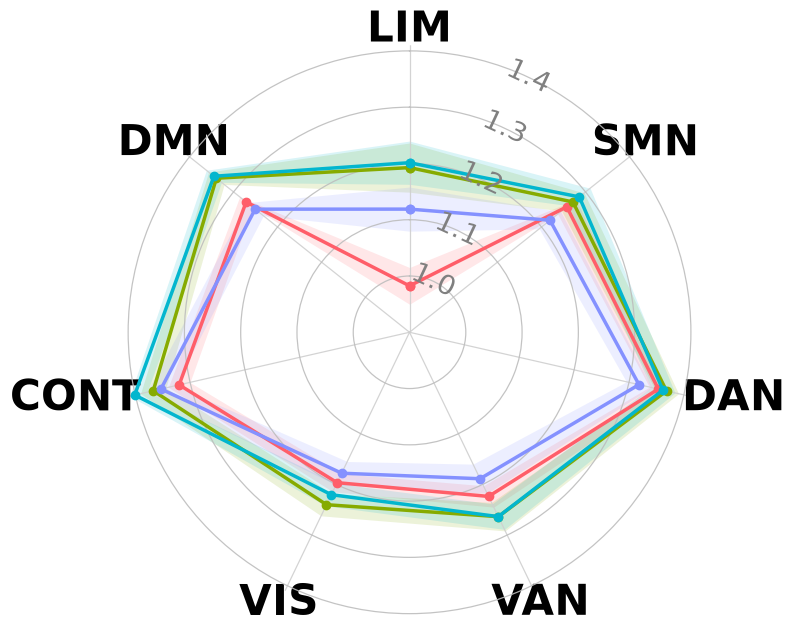

In [8]:
df = pd.read_csv(file_path)
df = preprocess_df(df, task_col=TASK_COL, tasks=tasks)

summary_df, mean_mat, std_mat, n_mat, networks = build_summary_table(
    df,
    networks=networks
)

os.makedirs(output_path, exist_ok=True)

plot_network_radarplot(
    mean_mat=mean_mat,
    std_mat=std_mat,
    n_mat=n_mat,
    networks=networks,
    tasks=tasks,
    figsize=(8, 8),
    labelsize=LABELSIZE,
    ticksize=TICKSIZE,
    titlesize=TITLESIZE,
    save_path=output_path,
    task_colors=['#ff5e69', '#86ab00', '#03b6ce', '#8491ff'],
    show=False
)

plot_network_all_task_radarplot(
    mean_mat=mean_mat,
    std_mat=std_mat,
    n_mat=n_mat,
    networks=networks,
    tasks=tasks,
    figsize=(8, 8),
    ticksize=TICKSIZE,
    labelsize=LABELSIZE,
    ymin = 0.9,
    ymax = 1.41,
    save_path=f"{output_path}/all_tasks.png",
    task_colors=['#ff5e69', '#86ab00', '#03b6ce', '#8491ff'],
)

# 3C: ANOVA

In [9]:
# Parameters 
anova_df_path = f'{base_path}/RESULTS/replication_dataset/anova/anova_results_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_rest_no_outliers.xlsx'
atlas_path = f"{base_path}/DATA/templates/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_2mm.nii.gz"
output_path = f'{base_path}/FIGURES/main/Fig_3/C'

task_names = ["Rest", "0Back", "1Back", "2Back"]
max_color = "#42033D"

In [10]:
f_values_df = pd.read_excel(anova_df_path)

print('Fraction of significant parcels:', np.sum(f_values_df['significance'])/len(f_values_df))
print('Mean η² of Limbic parcels:', f_values_df[f_values_df["name"].str.contains("Limbic", na=False)]['Partial_Eta_Squared'].mean(), f_values_df[f_values_df["name"].str.contains("Limbic", na=False)]['Partial_Eta_Squared'].std())
print('Mean η² of Default parcels:', f_values_df[f_values_df["name"].str.contains("Default", na=False)]['Partial_Eta_Squared'].mean(), f_values_df[f_values_df["name"].str.contains("Default", na=False)]['Partial_Eta_Squared'].std())

Fraction of significant parcels: 0.49
Mean η² of Limbic parcels: 0.25826535457712285 0.12177966321976262
Mean η² of Default parcels: 0.16668470374073938 0.08751474082916523


### Effect size map

In [11]:
effect_size = f_values_df['Partial_Eta_Squared'].values
effect_size = np.where(
    f_values_df["significance"].to_numpy(dtype=bool),
    effect_size,
    0.0
)

mapname = f"{output_path}/Partial_Eta_Squared.png"
os.makedirs(output_path, exist_ok=True)

plot_parcelwise_with_roi_surface_direct(
        matrix=effect_size,
        lh_annot_path=f"{base_path}/DATA/templates/lh.Schaefer2018_100Parcels_7Networks_order.annot",
        rh_annot_path=f"{base_path}/DATA/templates/rh.Schaefer2018_100Parcels_7Networks_order.annot",
        roi_img_path=None,
        img_name=mapname,
        max_color=max_color, 
        mesh="fsaverage6",
        label="Partial Eta Squared",
        inflate_fraction=0.70,
        show=False,
        vmin=0,
        vmax=0.3,
    )

[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6


### Effect size radarplot

In [12]:
# plotting parameters
network_order = ["Limbic", "SomMot", "DorsAttn", "SalVentAttn", "Vis", "Cont", "Default"]

LABELSIZE = 0
TICKSIZE = 18

In [13]:
# functions

def extract_mean_effect_sizes(anova_df, network_order):
    parcel_names = anova_df["name"].tolist()
    networks = [
        re.sub(r"_.*$", "", re.sub(r"^7Networks_[LR]H_", "", p))
        for p in parcel_names
    ]
    anova_df["Network"] = networks
    mean_effects = (
        anova_df.groupby("Network")["Partial_Eta_Squared"]
        .mean()
        .reindex(network_order, fill_value=0)
    )

    std_effects = (
            anova_df.groupby("Network")["Partial_Eta_Squared"]
            .std()
            .reindex(network_order, fill_value=0)
        )
    return mean_effects, std_effects

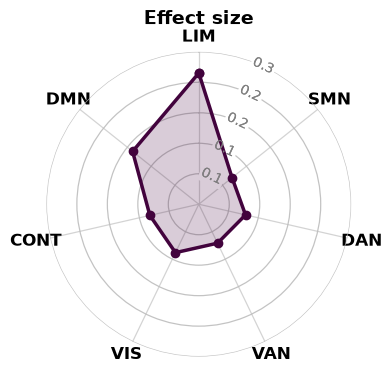

In [14]:
os.makedirs(output_path, exist_ok=True)

data = pd.read_excel(anova_df_path)
mean_effects, std_effects = extract_mean_effect_sizes(data, network_order)

mean_mat = mean_effects.to_frame(name="Effect size")

n_mat = pd.DataFrame(
    1,
    index=network_order,
    columns=["Effect size"]
)

std_mat = mean_mat * 0
n_mat = mean_mat * 0 + 1

plot_network_radarplot(
    mean_mat,
    std_mat,
    n_mat=n_mat,
    tasks=["Effect size"],
    networks=network_order,
    save_path=os.path.join(output_path, "mean_effect_sizes_by_network.png"),
    ymin=0,
    ymax=0.3,
    task_colors=[max_color]
)

# 3D: Singular Value Decomposition

In [20]:
# Data parameters

svd_root = f"{base_path}/RESULTS/replication_dataset/svd"
config_dirs = {
    "all":  f"{svd_root}/all"
}

figure_root = f"{base_path}/FIGURES/main/Fig_3/D"

atlas_path = f"{base_path}/DATA/templates/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_2mm.nii.gz"

os.makedirs(figure_root, exist_ok=True)

# Plotting parameters
FIG_DPI = 200
LABEL_SIZE = 26
TICK_SIZE = 20
TITLE_SIZE = 14
LINE_WIDTH = 2.0
MARKER_SIZE = 15
vmin, vmax = -0.2, 0.2

TASK_COLORS = {
    'Rest':  '#ff5e69',
    '0Back': '#86ab00',
    '1Back': '#03b6ce',
    '2Back': '#8491ff'
}

titles = ['Rest', '0-Back', '1-Back', '2-Back']

color1 = "#08547D"
color2 = "#E07B39"
custom_cmap = LinearSegmentedColormap.from_list("custom_cmap", [color1, "white", color2])

N_PCS_TO_PLOT = 2

In [21]:
from utils.svd import load_svd_result, compute_task_loading_summary

def style_ax(ax):
    """Common style for all plots."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=TICK_SIZE)
    return ax



def plot_brain_maps_for_config(config_name, result, output_dir, n_pcs=4):

    os.makedirs(output_dir, exist_ok=True)

    U = result["U"]
    var_explained = result["var_explained"]

    n_pcs = min(n_pcs, U.shape[1])

    for k in range(n_pcs):
        vec = U[:, k]

        out_name = os.path.join(
            output_dir,
            f"{config_name}_PC{k+1}_{var_explained[k]*100:.1f}_infl70.pct.png"
        )

        plot_parcelwise_with_roi_surface_direct(
            vec,
            lh_annot_path=f"{base_path}/DATA/templates/lh.Schaefer2018_100Parcels_7Networks_order.annot",
            rh_annot_path=f"{base_path}/DATA/templates/rh.Schaefer2018_100Parcels_7Networks_order.annot",
            img_name=out_name,
            inflate_fraction=0.7,
            vmin=vmin,
            vmax=vmax,
            colormap=custom_cmap,

        )


def plot_task_summary_bars(config_name, result, output_filename, n_pcs=4, add_subject_points=True):

    Vt = result["Vt"]
    var_explained = result["var_explained"]
    metadata = result["metadata"]
    tasks_in_this_config = result["tasks"]

    n_pcs = min(n_pcs, Vt.shape[0])

    fig, axes = plt.subplots(
        1, n_pcs,
        figsize=(8 * n_pcs, 5),
        sharey=True,
        dpi=FIG_DPI
    )

    if n_pcs == 1:
        axes = [axes]

    for pc_idx, ax in enumerate(axes):
        summary, tmp = compute_task_loading_summary(Vt, metadata, pc_idx)

        summary["Task"] = pd.Categorical(summary["Task"], categories=tasks_in_this_config, ordered=True)
        summary = summary.sort_values("Task")

        x = np.arange(len(summary))
        colors = [TASK_COLORS[t] for t in summary["Task"]]

        display(summary)
        ax.bar(
            x,
            summary["mean"],
            yerr=summary["std"],
            color=colors,
            edgecolor="none",
            width=0.72,
            alpha=0.6,
            capsize=4
        )

        if add_subject_points:
            for i, task in enumerate(summary["Task"]):
                vals = tmp.loc[tmp["Task"] == task, "loading"].values
                if len(vals) > 0:
                    jitter = np.linspace(-0.13, 0.13, len(vals)) if len(vals) > 1 else np.array([0.0])
                    ax.scatter(
                        np.full(len(vals), i) + jitter,
                        vals,
                        s=50,
                        alpha=0.7,
                        color=TASK_COLORS.get(task, "black"),
                        linewidths=0,
                        zorder=3
                    )

        ax.axhline(0, color="black", linewidth=0.9)
        ax.set_xticks(x)
        ax.set_xticklabels(titles, fontweight="bold")
        ax.set_ylim(vmin, vmax)


        style_ax(ax)

    axes[0].set_ylabel("Mean loadings", fontsize=LABEL_SIZE, fontweight="bold", labelpad=-50)
    axes[0].set_yticks([vmin, vmax])

    plt.tight_layout()
    plt.savefig(output_filename, dpi=FIG_DPI, bbox_inches="tight")
    plt.show()

,Task,mean,std
3,Rest,0.095444,0.023346
0,0Back,0.072468,0.025736
1,1Back,0.075352,0.027863
2,2Back,0.077218,0.025720


,Task,mean,std
3,Rest,-0.091209,0.049555
0,0Back,0.030865,0.053497
1,1Back,0.051335,0.059140
2,2Back,0.054930,0.072342


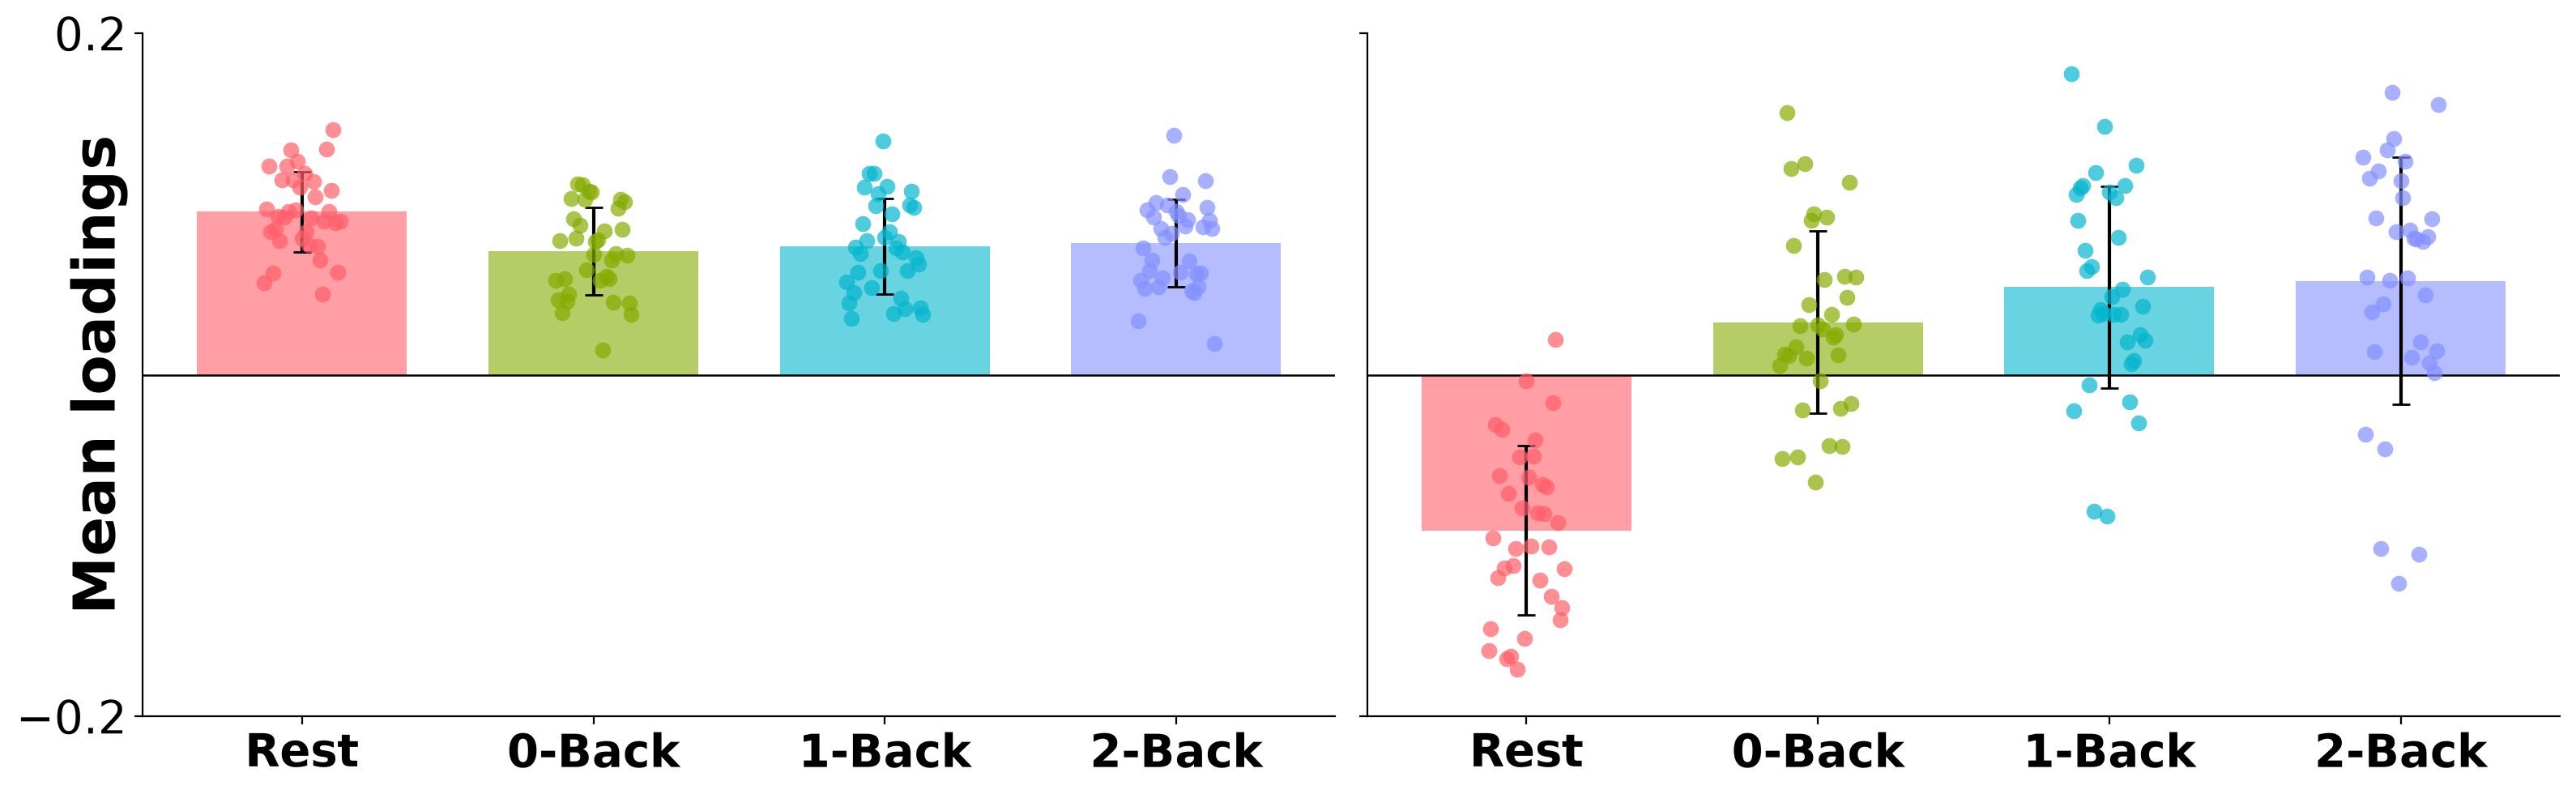

[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6
[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6


In [22]:
# Load results for all configurations
results = {}
for config_name, config_dir in config_dirs.items():
    results[config_name] = load_svd_result(
        config_dir,
        orient_components=False
    )

    U = results[config_name]["U"]
    Vt = results[config_name]["Vt"]

    # Arbitrary orientation of the first component
    U[:, 0] *= -1
    Vt[0, :] *= -1

# Task-summary barplots
for config_name, result in results.items():
    out_name = f"{figure_root}/task_summary_barplot_{config_name}.png"
    plot_task_summary_bars(
        config_name=config_name,
        result=result,
        output_filename=out_name,
        n_pcs=N_PCS_TO_PLOT,
        add_subject_points=True
    )

# Brain maps
for config_name, result in results.items():
    brain_out_dir = os.path.join(figure_root, "brain_maps", config_name)
    plot_brain_maps_for_config(
        config_name=config_name,
        result=result,
        output_dir=brain_out_dir,
        n_pcs=N_PCS_TO_PLOT
    )


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


NETWORK_ORDER = [
    "Limbic", "SomMot", "DorsAttn",
    "SalVentAttn", "Vis", "Cont", "Default"
]

NETWORK_LABELS = {
    "Limbic": "LIM",
    "SomMot": "SMN",
    "DorsAttn": "DAN",
    "SalVentAttn": "VAN",
    "Vis": "VIS",
    "Cont": "CONT",
    "Default": "DMN",
}


def load_schaefer_networks(csv_path):
    """Load Schaefer network labels in parcel order."""

    df = pd.read_csv(csv_path, usecols=[0, 1])
    roi_names = df.iloc[:, 1].astype(str)

    networks = roi_names.str.extract(
        r"7Networks_[LR]H_([^_]+)_", expand=False
    )

    if networks.isna().any():
        raise ValueError(
            "Some ROI names do not match the expected "
            "Schaefer 7-network naming convention."
        )

    unknown = set(networks) - set(NETWORK_ORDER)
    if unknown:
        raise ValueError(f"Unknown networks: {unknown}")

    return networks.tolist()


def compute_network_mean_profile(
    loadings_vec,
    parcel_networks,
    network_order=NETWORK_ORDER
):
    """Compute the mean parcel score for each network."""

    vec = np.asarray(loadings_vec, dtype=float)

    if len(vec) != len(parcel_networks):
        raise ValueError(
            "The number of component scores does not match "
            "the number of parcel labels."
        )

    df = pd.DataFrame({
        "loading": vec,
        "network": parcel_networks
    })

    return (
        df.groupby("network")["loading"]
        .mean()
        .reindex(network_order)
        .to_numpy(dtype=float)
    )


def plot_single_profile_radar(
    profile,
    networks=NETWORK_ORDER,
    network_labels=NETWORK_LABELS,
    figsize=(4.2, 4.2),
    color="#808080",
    alpha_fill=0.18,
    linewidth=1.6,
    markersize=4.0,
    ymin=None,
    ymax=None,
    yticks_fixed=None,
    title=None,
    save_path=None,
    show=True,
    labelsize=11,
    ticksize=9,
    titlesize=14,
    xpad=-2,
):
    """Plot a network-averaged component profile as a radar chart."""

    profile = np.asarray(profile, dtype=float)

    if len(profile) != len(networks):
        raise ValueError(
            "Profile length must match the number of networks."
        )

    if not np.all(np.isfinite(profile)):
        raise ValueError("Profile contains NaN or infinite values.")

    # Automatically determine symmetric radial limits.
    if ymin is None or ymax is None:
        limit = max(np.max(np.abs(profile)) * 1.15, 0.01)
        ymin, ymax = -limit, limit

    if ymin >= ymax:
        raise ValueError("ymin must be smaller than ymax.")

    if not ymin <= 0 <= ymax:
        raise ValueError("Radial limits must include zero.")

    if yticks_fixed is None:
        yticks = np.linspace(ymin, ymax, 5)
    else:
        yticks = np.asarray(yticks_fixed, dtype=float)
        if np.any((yticks < ymin) | (yticks > ymax)):
            raise ValueError("Radial ticks must lie within the limits.")

    # Shift values so negative scores can be displayed on a polar axis.
    radius = profile - ymin
    tick_radius = yticks - ymin

    n_networks = len(networks)
    angles = np.linspace(0, 2 * np.pi, n_networks, endpoint=False)
    angles_closed = np.r_[angles, angles[0]]
    radius_closed = np.r_[radius, radius[0]]

    fig, ax = plt.subplots(
        figsize=figsize,
        subplot_kw={"polar": True}
    )

    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_ylim(0, ymax - ymin)

    # Grid
    ax.set_yticks(tick_radius)
    ax.set_yticklabels([])

    ax.yaxis.grid(
        True, color="#bdbdbd", linewidth=0.85, alpha=0.9
    )
    ax.xaxis.grid(
        True, color="#cfcfcf", linewidth=0.85, alpha=0.9
    )
    ax.spines["polar"].set_visible(False)

    theta_full = np.linspace(0, 2 * np.pi, 300)

    # Outer boundary
    ax.plot(
        theta_full,
        np.full_like(theta_full, ymax - ymin),
        color="#bdbdbd",
        linewidth=0.85,
        alpha=0.9,
        zorder=1
    )

    # Zero reference circle
    ax.plot(
        theta_full,
        np.full_like(theta_full, -ymin),
        color="#666666",
        linewidth=1.0,
        alpha=0.85,
        zorder=2
    )

    # Network labels
    ax.set_xticks(angles)
    ax.set_xticklabels(
        [network_labels[n] for n in networks],
        fontsize=labelsize,
        color="black",
        fontweight="bold"
    )
    ax.tick_params(axis="x", pad=xpad)

    # Radial tick labels
    theta_label = np.deg2rad(25)

    for value, r in zip(yticks, tick_radius):
        ax.text(
            theta_label,
            r,
            f"{value:.2f}",
            fontsize=ticksize,
            color="gray",
            rotation=-25,
            rotation_mode="anchor",
            ha="center",
            va="center",
            zorder=4,
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                boxstyle="round,pad=0.12"
            )
        )

    # Network profile
    ax.fill(
        angles_closed,
        radius_closed,
        color=color,
        alpha=alpha_fill,
        linewidth=0,
        zorder=5
    )

    ax.plot(
        angles_closed,
        radius_closed,
        color=color,
        linewidth=linewidth,
        marker="o",
        markersize=markersize,
        zorder=6
    )

    if title is not None:
        ax.set_title(
            title,
            fontsize=titlesize,
            fontweight="bold",
            pad=18
        )

    plt.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

    if show:
        plt.show()

    plt.close(fig)


def plot_network_mean_radar(
    config_name,
    result,
    parcel_networks,
    output_dir,
    n_pcs=4,
    color="#808080",
    ymin=None,
    ymax=None,
    yticks_fixed=None,
    show=False
):
    """Generate network-averaged radar plots for SVD components."""

    os.makedirs(output_dir, exist_ok=True)

    # U contains parcel-level component scores.
    U = np.asarray(result["U"], dtype=float)

    if U.ndim != 2 or U.shape[0] != len(parcel_networks):
        raise ValueError(
            f"Expected U to have shape (n_parcels, n_components), "
            f"but got {U.shape} for {len(parcel_networks)} parcels."
        )

    n_pcs = min(n_pcs, U.shape[1])

    for pc_idx in range(n_pcs):

        # Preserve the orientation of the original SVD results.
        vec = U[:, pc_idx]

        profile = compute_network_mean_profile(
            vec,
            parcel_networks,
            network_order=NETWORK_ORDER
        )

        save_path = os.path.join(
            output_dir,
            f"network_mean_radar_{config_name}_PC{pc_idx + 1}.png"
        )

        plot_single_profile_radar(
            profile=profile,
            color=color,
            title=f"{config_name} - PC{pc_idx + 1}",
            ymin=ymin,
            ymax=ymax,
            yticks_fixed=yticks_fixed,
            save_path=save_path,
            show=show
        )


In [ ]:
schaefer_csv_path = (
    f"{base_path}/DATA/templates/"
    "Schaefer2018_100Parcels_7Networks_order_"
    "FSLMNI152_2mm.Centroid_RAS.csv"
)

parcel_networks = load_schaefer_networks(schaefer_csv_path)

# Check that the number of network labels matches the SVD parcels
for config_name, result in results.items():
    assert result["U"].shape[0] == len(parcel_networks), (
        f"Parcel count mismatch for {config_name}"
    )

# Generate network radar plots
for config_name, result in results.items():

    output_dir = os.path.join(
        figure_root,
        "network_radars_mean",
        config_name
    )

    plot_network_mean_radar(
        config_name=config_name,
        result=result,
        parcel_networks=parcel_networks,
        output_dir=output_dir,
        n_pcs=N_PCS_TO_PLOT,
        color="#808080",
        ymin=-0.2,
        ymax=0.2,
        yticks_fixed=[-0.2, -0.1, 0.0, 0.1, 0.2],
        show=False
    )
